# Week 6-B: Hybrid Lexical-Semantic Passage Fidelity Routing

### Primary Research Question:
> **Do lexical BM25 relevance and pretrained semantic relevance contain complementary routing information, such that combining them improves passage-fidelity routing beyond either signal alone?**

In Week 6-A, we investigated passage fidelity routing and established that:
- $R_1$ (Pretrained Semantic Top-$k$ via zero-shot bi-encoder) significantly outperforms the standard $R_0$ BM25 prefix baseline at $k=4$ ($F_1 = 0.3913$ vs $0.3596$, $+3.17$ points) while saving context tokens.
- $R_2$ (Evidence-supervised learned router) achieved high evidence overlap recall but did not translate into higher downstream answer generation quality ($F_1 = 0.3572$ at $k=4$).

Week 6-B investigates whether **fusing** lexical BM25 ranking and pretrained semantic ranking can combine the precision of semantic matching with the keyword coverage of BM25.

### Routers Evaluated:
1. **$R_0$ (BM25 Prefix Baseline):** First $k$ BM25 retrieved passages.
2. **$R_1$ (Pure Semantic Top-$k$):** Frozen MiniLM bi-encoder cosine similarity.
3. **$R_2$ (Learned Evidence Router):** Historical supervised router from Week 6-A.
4. **$R_3$ (Fixed Score Fusion):** $h_i(lpha) = lpha 	ilde{b}_i + (1 - lpha) 	ilde{s}_i$, with $lpha \in \{0.00, 0.25, 0.50, 0.75, 1.00\}$. Selected on INTERNAL-VAL only!
5. **$R_4$ (Reciprocal Rank Fusion - RRF):** $RRF_i = rac{1}{60 + r_{\text{BM25}}(i)} + rac{1}{60 + r_{\text{sem}}(i)}$ (parameter-light rank fusion).
6. **$R_5$ (Rank-Sum Baseline):** $\text{score}_i = -r_{\text{BM25}}(i) - r_{\text{sem}}(i)$.


## Section 1: Setup, Configuration, and Canonical W6-A Baseline Artifacts


In [1]:
import os
import sys
import json
import time
import copy
from pathlib import Path
import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from transformers import AutoTokenizer

# Resolve Project Root across any working directory
_curr = Path.cwd().resolve()
candidates = [_curr, _curr.parent, _curr.parent.parent]
PROJECT_ROOT = next((p for p in candidates if (p / "src").is_dir() and (p / "configs").is_dir()), _curr)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)

SARA_ROOT = PROJECT_ROOT / "Baselines/SARA-main"
if str(SARA_ROOT) not in sys.path:
    sys.path.append(str(SARA_ROOT))

import src
if hasattr(src, "__path__") and str(SARA_ROOT / "src") not in src.__path__:
    src.__path__.append(str(SARA_ROOT / "src"))

from src.week6.data import (
    build_w6_dataset_bundle,
    routing_collate_fn,
    match_passages_to_gold_evidence,
    load_retrieval_records,
    audit_w6_split_isolation,
)
from src.week6.models import PretrainedSemanticScorer
from src.week6.routing import (
    route_r0_bm25_prefix,
    route_r1_semantic_topk,
    validate_routing_assignment,
    build_routed_sara_prompt,
    extract_routed_sara_embeddings,
)
from src.week6.hybrid_routing import (
    normalize_scores_minmax,
    normalize_scores_zscore,
    compute_ranks_from_scores,
    fuse_bm25_semantic_scores,
    route_r3_fixed_fusion,
    compute_rrf_scores,
    route_r4_rrf,
    compute_rank_sum_scores,
    route_r5_rank_sum,
    select_best_alpha_from_internal_val,
)
from src.week6.disagreement import (
    compute_jaccard_overlap,
    compute_differing_passages_count,
    compute_rank_correlation,
    extract_future_gate_features_per_query,
    build_disagreement_analysis_dataframe,
)
from src.week6.evaluation import (
    evaluate_routing_quality,
    compute_selected_rank_distribution,
    compute_routing_diversity,
    load_canonical_r0_results,
    run_sara_generation_for_routed_policy,
    paper_clustered_bootstrap_comparison,
)

# Load Week 6-B Config
with open("configs/week6/hybrid_routing.yaml", "r") as f:
    cfg = yaml.safe_load(f)

# Ensure output directories exist
for p_key in [
    "routing_assignments_dir", "sara_generations_dir", "tables_dir",
    "figures_dir", "bootstrap_dir", "diagnostics_dir", "smoke_dir", "logs_dir"
]:
    Path(cfg["paths"][p_key]).mkdir(parents=True, exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
BUDGETS = cfg["budgets"]
ALPHA_GRID = cfg["alpha_grid"]
RRF_C = float(cfg["rrf"]["c"])

print(f"Project root: {PROJECT_ROOT}")
print(f"Execution device: {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
print(f"Fixed routing budgets: k={BUDGETS}")
print(f"Alpha fusion grid: {ALPHA_GRID}")
print(f"RRF constant c: {RRF_C}")


/home/gunavenkat/Downloads/CS787-RAG-Project/sara_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
INFO:datasets:PyTorch version 2.14.0 available.
/home/gunavenkat/Downloads/CS787-RAG-Project/sara_env/lib/python3.11/site-packages/nltk/downloader.py:1076: UserWarning: NLTK will not authorize the non-private download directory '/home/gunavenkat/nltk_data': it (or an ancestor) is world- or group-writable, so another local user could plant files there. Choose a private location such as ~/nltk_data.
  for msg in self.incr_download(info_or_id, download_dir, force):


Project root: /home/gunavenkat/Downloads/CS787-RAG-Project
Execution device: cuda
GPU: NVIDIA TITAN RTX
Fixed routing budgets: k=[2, 4, 6]
Alpha fusion grid: [0.0, 0.25, 0.5, 0.75, 1.0]
RRF constant c: 60.0


[nltk_data] Downloading package stopwords to
[nltk_data]     /home/gunavenkat/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


### Load and Inspect Canonical Week 6-A Results (R0, R1, R2)


In [2]:
# Load canonical Week 6-A main results table
w6a_table_path = Path(cfg["paths"]["w6a_main_results"])
if w6a_table_path.exists():
    df_w6a_results = pd.read_csv(w6a_table_path)
    print("Canonical Week 6-A Main Results Table Loaded:")
    display(df_w6a_results)
else:
    print(f"WARNING: Canonical Week 6-A table not found at {w6a_table_path}")


Canonical Week 6-A Main Results Table Loaded:


,router,k,answer_f1_mean,answer_f1_std,context_tokens_mean,latency_mean_sec
0,R0_bm25_prefix,2,0.303835,0.379664,526.523810,0.000000
1,R0_bm25_prefix,4,0.359601,0.393989,938.121212,0.000000
2,R0_bm25_prefix,6,0.385699,0.390981,1351.116883,0.000000
3,R1_semantic_topk,2,0.312678,0.381688,509.636364,1.836474
4,R1_semantic_topk,4,0.391333,0.400429,921.073593,2.684737
5,R1_semantic_topk,6,0.395345,0.393080,1325.090909,3.629630
6,R2_learned_router,2,0.298276,0.374743,565.398268,1.812983
7,R2_learned_router,4,0.357210,0.390746,994.714286,2.834549
8,R2_learned_router,6,0.369367,0.392932,1422.225108,3.909536


## Section 2: Split Integrity and Dataset Bundles (TRAIN-FIT / INTERNAL-VAL / DEV)


In [3]:
# Build unified dataset bundles with strict paper-level split isolation audit
train_bundle, val_bundle, dev_bundle = build_w6_dataset_bundle(
    train_fit_manifest_path=cfg["paths"]["train_fit_manifest"],
    internal_val_manifest_path=cfg["paths"]["internal_val_manifest"],
    train_retrieval_path=cfg["paths"]["train_retrieval_file"],
    dev_retrieval_path=cfg["paths"]["dev_retrieval_file"],
    dev_supervision_path="results/week5/supervision/dev_allocation_supervision.csv",
    qasper_train_split=cfg["paths"]["qasper_train_split"],
    qasper_dev_split=cfg["paths"]["qasper_dev_split"],
    raw_arrow_train=cfg["paths"]["raw_arrow_train"],
    raw_arrow_val=cfg["paths"]["raw_arrow_val"],
    qasper_manifest=cfg["paths"]["qasper_manifest"],
    tokenizer_name="sentence-transformers/all-MiniLM-L6-v2",
)

print(f"Split Isolation Confirmed:")
print(f"  TRAIN-FIT: {len(train_bundle['question_ids'])} questions across {len(set(train_bundle['paper_ids']))} papers")
print(f"  INTERNAL-VAL: {len(val_bundle['question_ids'])} questions across {len(set(val_bundle['paper_ids']))} papers")
print(f"  DEV: {len(dev_bundle['question_ids'])} questions across {len(set(dev_bundle['paper_ids']))} papers")
print(f"  TEST split: STRICTLY UNTOUCHED and NEVER LOADED.")


INFO:src.week6.data:Split isolation audit passed: TRAIN-FIT=1746q/656p, INTERNAL-VAL=342q/116p, DEV=231q/86p. Overlaps=0.


Split Isolation Confirmed:
  TRAIN-FIT: 1746 questions across 656 papers
  INTERNAL-VAL: 342 questions across 116 papers
  DEV: 231 questions across 86 papers
  TEST split: STRICTLY UNTOUCHED and NEVER LOADED.


## Section 3: Lexical BM25 and Semantic Score Audits


Computing MiniLM semantic relevance scores for INTERNAL-VAL...
Computing MiniLM semantic relevance scores for DEV...
Score shapes:
  INTERNAL-VAL BM25: (342, 10), Semantic: (342, 10)
  DEV BM25: (231, 10), Semantic: (231, 10)


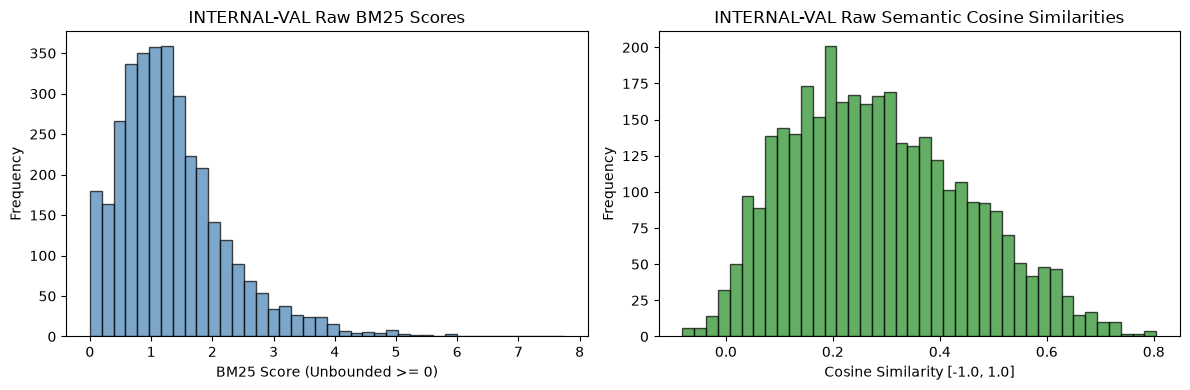

In [4]:
# 1. Load retrieval records for INTERNAL-VAL and DEV
train_records = load_retrieval_records(cfg["paths"]["train_retrieval_file"])
dev_records = load_retrieval_records(cfg["paths"]["dev_retrieval_file"])

val_qids = val_bundle["question_ids"]
val_items = [train_records[qid] for qid in val_qids]

dev_qids = dev_bundle["question_ids"]
dev_items = [dev_records[qid] for qid in dev_qids]

# 2. Extract BM25 scores
val_bm25_scores = np.array([[float(p.get("score", 0.0)) for p in item["passages"][:10]] for item in val_items], dtype=np.float32)
dev_bm25_scores = np.array([[float(p.get("score", 0.0)) for p in item["passages"][:10]] for item in dev_items], dtype=np.float32)

# 3. Compute or load Pretrained Semantic Similarity Scores (MiniLM bi-encoder)
r1_scorer = PretrainedSemanticScorer(model_name="sentence-transformers/all-MiniLM-L6-v2", device=DEVICE)

print("Computing MiniLM semantic relevance scores for INTERNAL-VAL...")
val_sem_scores_list = []
for item in val_items:
    q_text = item["question"]
    p_texts = [p.get("text", "") for p in item["passages"][:10]]
    s = r1_scorer.score_query_passages(q_text, p_texts, device=DEVICE).cpu().numpy()
    val_sem_scores_list.append(s)
val_sem_scores = np.stack(val_sem_scores_list, axis=0)

print("Computing MiniLM semantic relevance scores for DEV...")
dev_sem_scores_list = []
for item in dev_items:
    q_text = item["question"]
    p_texts = [p.get("text", "") for p in item["passages"][:10]]
    s = r1_scorer.score_query_passages(q_text, p_texts, device=DEVICE).cpu().numpy()
    dev_sem_scores_list.append(s)
dev_sem_scores = np.stack(dev_sem_scores_list, axis=0)

print(f"Score shapes:")
print(f"  INTERNAL-VAL BM25: {val_bm25_scores.shape}, Semantic: {val_sem_scores.shape}")
print(f"  DEV BM25: {dev_bm25_scores.shape}, Semantic: {dev_sem_scores.shape}")

# Plot raw score distributions to illustrate the scale mismatch
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(val_bm25_scores.flatten(), bins=40, color="steelblue", alpha=0.7, edgecolor="black")
axes[0].set_title("INTERNAL-VAL Raw BM25 Scores")
axes[0].set_xlabel("BM25 Score (Unbounded >= 0)")
axes[0].set_ylabel("Frequency")

axes[1].hist(val_sem_scores.flatten(), bins=40, color="forestgreen", alpha=0.7, edgecolor="black")
axes[1].set_title("INTERNAL-VAL Raw Semantic Cosine Similarities")
axes[1].set_xlabel("Cosine Similarity [-1.0, 1.0]")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()


## Section 4: Score Normalization (Per-Query Min-Max)


In [5]:
# Demonstrate Per-Query Min-Max Normalization:
#   tilde_s_i = (s_i - min_j s_j) / (max_j s_j - min_j s_j + eps)
# Handled safely for constant-score vectors (assigns uniform 1.0).

sample_b = val_bm25_scores[0]
sample_s = val_sem_scores[0]

sample_b_norm = normalize_scores_minmax(sample_b)
sample_s_norm = normalize_scores_minmax(sample_s)

df_demo_norm = pd.DataFrame({
    "Rank": list(range(1, 11)),
    "Raw_BM25": sample_b,
    "Norm_BM25": sample_b_norm,
    "Raw_Semantic": sample_s,
    "Norm_Semantic": sample_s_norm,
})

print("Sample Per-Query Score Normalization for Query 0:")
display(df_demo_norm)


Sample Per-Query Score Normalization for Query 0:


,Rank,Raw_BM25,Norm_BM25,Raw_Semantic,Norm_Semantic
0,1,2.953078,1.000000,0.499970,0.578215
1,2,1.958736,0.427551,0.384145,0.000000
2,3,1.753579,0.309441,0.543492,0.795488
3,4,1.641748,0.245059,0.548585,0.820910
4,5,1.580972,0.210070,0.457517,0.366286
5,6,1.569268,0.203332,0.477051,0.463802
6,7,1.475267,0.149215,0.584459,1.000000
7,8,1.327925,0.064389,0.537222,0.764185
8,9,1.233266,0.009894,0.402410,0.091180
9,10,1.216081,0.000000,0.397903,0.068682


## Section 5: R3 Fixed Score Fusion


In [6]:
# R3 Linear Score Fusion:
#   h_i(alpha) = alpha * tilde_b_i + (1 - alpha) * tilde_s_i
# Evaluated across alpha in {0.00, 0.25, 0.50, 0.75, 1.00}

print("Demonstrating fused score ranking across alpha grid for sample query:")
fused_demo = {}
for a in ALPHA_GRID:
    fused_scores = fuse_bm25_semantic_scores(sample_b, sample_s, alpha=a)
    sel = route_r3_fixed_fusion(sample_b, sample_s, alpha=a, k=4)
    fused_demo[f"alpha_{a:.2f}"] = [x + 1 for x in sel]

display(pd.DataFrame(list(fused_demo.items()), columns=["Alpha", "Selected_BM25_Ranks_k4"]))


Demonstrating fused score ranking across alpha grid for sample query:


,Alpha,Selected_BM25_Ranks_k4
0,alpha_0.00,"[3, 4, 7, 8]"
1,alpha_0.25,"[1, 3, 4, 7]"
2,alpha_0.50,"[1, 3, 4, 7]"
3,alpha_0.75,"[1, 3, 4, 7]"
4,alpha_1.00,"[1, 2, 3, 4]"


## Section 6: R4 Reciprocal Rank Fusion (RRF) and R5 Rank-Sum


In [7]:
# R4 Reciprocal Rank Fusion:
#   RRF_i = 1 / (60 + r_BM25(i)) + 1 / (60 + r_sem(i))
# R5 Rank-Sum Baseline:
#   score_i = -r_BM25(i) - r_sem(i)

sample_b_ranks = np.arange(1, 11)
sample_s_ranks = compute_ranks_from_scores(sample_s, reverse=True)

sample_rrf = compute_rrf_scores(sample_b_ranks, sample_s_ranks, c=RRF_C)
sample_r4_sel = route_r4_rrf(sample_b_ranks, sample_s_ranks, k=4, c=RRF_C)
sample_r5_sel = route_r5_rank_sum(sample_b_ranks, sample_s_ranks, k=4)

print(f"Sample R4 RRF Selected Ranks (k=4): {[x + 1 for x in sample_r4_sel]}")
print(f"Sample R5 Rank-Sum Selected Ranks (k=4): {[x + 1 for x in sample_r5_sel]}")


Sample R4 RRF Selected Ranks (k=4): [1, 3, 4, 7]
Sample R5 Rank-Sum Selected Ranks (k=4): [1, 3, 4, 7]


## Section 7: Routing Invariant Checks


In [8]:
# Verify all Week 6-B routing invariants across INTERNAL-VAL:
# 1. Exactly k passages chosen.
# 2. Exactly 10 - k passages compressed.
# 3. alpha = 0.0 matches R1 semantic top-k identically.
# 4. alpha = 1.0 matches R0 BM25 prefix identically.
# 5. RRF produces valid k-subsets.

for k in BUDGETS:
    for i in range(len(val_items)):
        b_sc = val_bm25_scores[i]
        s_sc = val_sem_scores[i]
        b_rnk = np.arange(1, 11)
        s_rnk = compute_ranks_from_scores(s_sc, reverse=True)

        # Baseline selections
        r0_sel = route_r0_bm25_prefix(k=k, n_passages=10)
        r1_sel = route_r1_semantic_topk(s_sc, k=k)

        # R3 selections
        sel_a0 = route_r3_fixed_fusion(b_sc, s_sc, alpha=0.0, k=k)
        sel_a1 = route_r3_fixed_fusion(b_sc, s_sc, alpha=1.0, k=k)

        assert sel_a0 == r1_sel, f"Invariant violation: alpha=0.0 != R1 at query {i}, k={k}"
        assert sel_a1 == r0_sel, f"Invariant violation: alpha=1.0 != R0 at query {i}, k={k}"

        # R4 selection
        sel_r4 = route_r4_rrf(b_rnk, s_rnk, k=k, c=RRF_C)
        validate_routing_assignment(sel_r4, k=k, total_passages=10)

print(f"All Week 6-B routing invariants VERIFIED across all {len(val_items)} INTERNAL-VAL queries for k={BUDGETS}!")


All Week 6-B routing invariants VERIFIED across all 342 INTERNAL-VAL queries for k=[2, 4, 6]!


## Section 8: Stage A Cheap Diagnostics on INTERNAL-VAL


In [9]:
# Evaluate evidence recall@k, precision@k, and routing diversity across alpha grid and R4
val_labels = val_bundle["labels"]  # (N_val, 10)

routing_diag_rows = []
for k in BUDGETS:
    # 1. R0 baseline
    r0_assignments = [route_r0_bm25_prefix(k=k, n_passages=10) for _ in range(len(val_items))]
    r0_rec = np.mean([val_labels[i, r0_assignments[i]].sum() / max(val_labels[i].sum(), 1.0) for i in range(len(val_items))])
    r0_prec = np.mean([val_labels[i, r0_assignments[i]].sum() / float(k) for i in range(len(val_items))])
    routing_diag_rows.append({"router": "R0_bm25_prefix", "k": k, "alpha": 1.0, "evidence_recall": r0_rec, "evidence_precision": r0_prec, "jaccard_vs_r0": 1.0, "jaccard_vs_r1": float(np.mean([compute_jaccard_overlap(r0_assignments[i], route_r1_semantic_topk(val_sem_scores[i], k=k)) for i in range(len(val_items))]))})

    # 2. R1 pure semantic
    r1_assignments = [route_r1_semantic_topk(val_sem_scores[i], k=k) for i in range(len(val_items))]
    r1_rec = np.mean([val_labels[i, r1_assignments[i]].sum() / max(val_labels[i].sum(), 1.0) for i in range(len(val_items))])
    r1_prec = np.mean([val_labels[i, r1_assignments[i]].sum() / float(k) for i in range(len(val_items))])
    routing_diag_rows.append({"router": "R1_semantic_topk", "k": k, "alpha": 0.0, "evidence_recall": r1_rec, "evidence_precision": r1_prec, "jaccard_vs_r0": float(np.mean([compute_jaccard_overlap(r1_assignments[i], r0_assignments[i]) for i in range(len(val_items))])), "jaccard_vs_r1": 1.0})

    # 3. R3 across alpha grid
    for a in ALPHA_GRID:
        r3_assignments = [route_r3_fixed_fusion(val_bm25_scores[i], val_sem_scores[i], alpha=a, k=k) for i in range(len(val_items))]
        r3_rec = np.mean([val_labels[i, r3_assignments[i]].sum() / max(val_labels[i].sum(), 1.0) for i in range(len(val_items))])
        r3_prec = np.mean([val_labels[i, r3_assignments[i]].sum() / float(k) for i in range(len(val_items))])
        j_r0 = float(np.mean([compute_jaccard_overlap(r3_assignments[i], r0_assignments[i]) for i in range(len(val_items))]))
        j_r1 = float(np.mean([compute_jaccard_overlap(r3_assignments[i], r1_assignments[i]) for i in range(len(val_items))]))
        routing_diag_rows.append({"router": f"R3_alpha_{a:.2f}", "k": k, "alpha": a, "evidence_recall": r3_rec, "evidence_precision": r3_prec, "jaccard_vs_r0": j_r0, "jaccard_vs_r1": j_r1})

    # 4. R4 RRF
    r4_assignments = [route_r4_rrf(np.arange(1, 11), compute_ranks_from_scores(val_sem_scores[i], reverse=True), k=k, c=RRF_C) for i in range(len(val_items))]
    r4_rec = np.mean([val_labels[i, r4_assignments[i]].sum() / max(val_labels[i].sum(), 1.0) for i in range(len(val_items))])
    r4_prec = np.mean([val_labels[i, r4_assignments[i]].sum() / float(k) for i in range(len(val_items))])
    j_r0 = float(np.mean([compute_jaccard_overlap(r4_assignments[i], r0_assignments[i]) for i in range(len(val_items))]))
    j_r1 = float(np.mean([compute_jaccard_overlap(r4_assignments[i], r1_assignments[i]) for i in range(len(val_items))]))
    routing_diag_rows.append({"router": "R4_rrf", "k": k, "alpha": np.nan, "evidence_recall": r4_rec, "evidence_precision": r4_prec, "jaccard_vs_r0": j_r0, "jaccard_vs_r1": j_r1})

df_diag = pd.DataFrame(routing_diag_rows)
df_diag.to_csv(Path(cfg["paths"]["tables_dir"]) / "w6b_routing_quality.csv", index=False)
print("Stage A Cheap Routing Diagnostics Summary:")
display(df_diag)


Stage A Cheap Routing Diagnostics Summary:


,router,k,alpha,evidence_recall,evidence_precision,jaccard_vs_r0,jaccard_vs_r1
0,R0_bm25_prefix,2,1.00,0.274576,0.342105,1.000000,0.246589
1,R1_semantic_topk,2,0.00,0.336000,0.385965,0.246589,1.000000
2,R3_alpha_0.00,2,0.00,0.336000,0.385965,0.246589,1.000000
3,R3_alpha_0.25,2,0.25,0.348865,0.400585,0.374269,0.748538
4,R3_alpha_0.50,2,0.50,0.338530,0.399123,0.598441,0.456140
5,R3_alpha_0.75,2,0.75,0.311256,0.378655,0.821637,0.311891
6,R3_alpha_1.00,2,1.00,0.274576,0.342105,1.000000,0.246589
7,R4_rrf,2,NaN,0.326009,0.391813,0.525341,0.512671
8,R0_bm25_prefix,4,1.00,0.487737,0.323830,1.000000,0.349373
9,R1_semantic_topk,4,0.00,0.559378,0.354532,0.349373,1.000000


## Section 9: Stage B Downstream SARA Generation on INTERNAL-VAL


Loading SARA checkpoint: /home/gunavenkat/Downloads/CS787-RAG-Project/Baselines/SARA-main/checkpoints/finetune/sara_qasper_proj_lr5e4_seed42


`torch_dtype` is deprecated! Use `dtype` instead!
Loading checkpoint shards: 100%|██████████| 3/3 [00:00<00:00, 118.04it/s]
Some weights of XMistralForCausalLM were not initialized from the model checkpoint at mistralai/Mistral-7B-Instruct-v0.2 and are newly initialized: ['projector.projector.0.bias', 'projector.projector.0.weight', 'projector.projector.2.bias', 'projector.projector.2.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
The new embeddings will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nlp.stanford.edu/~johnhew/vocab-expansion.html. To disable this, use `mean_resizing=False`
The new lm_head weights will be initialized from a multivariate normal distribution that has old embeddings' mean and covariance. As described in this article: https://nlp.stanford.edu/~johnhew/vocab-expansion.html. To disable this, use `

Loading train/val SFR embeddings cache...


INFO:src.week6.evaluation:Loaded 342 existing records from cache: results/week6/hybrid_routing/sara_generations/cache_val_R3_a0.00_k2.jsonl



--- Evaluating INTERNAL-VAL for R3 (alpha=0.00) at k=2 ---


...

Evaluating k=6: 100%|██████████| 342/342 [00:00<00:00, 184424.27it/s]


  Result: F1 = 0.4237 +/- 0.4193, tokens = 1358.6

--- Evaluating INTERNAL-VAL for R3 (alpha=1.00) at k=6 ---


INFO:src.week6.evaluation:Loaded 342 existing records from cache: results/week6/hybrid_routing/sara_generations/cache_val_R3_a1.00_k6.jsonl
Evaluating k=6: 100%|██████████| 342/342 [00:00<00:00, 195562.64it/s]

  Result: F1 = 0.4071 +/- 0.4117, tokens = 1365.0
INTERNAL-VAL Downstream SARA Generation Results:


,budget,alpha,answer_f1_mean,answer_f1_std,context_tokens_mean,latency_mean_sec
0,2,0.00,0.336344,0.398056,507.745614,1.640774
1,2,0.25,0.334832,0.396307,514.067251,1.703650
2,2,0.50,0.344874,0.400464,525.815789,1.710056
3,2,0.75,0.334902,0.397486,535.654971,1.774893
4,2,1.00,0.319215,0.391030,533.976608,1.757232
5,4,0.00,0.386269,0.410171,927.172515,2.582743
6,4,0.25,0.378393,0.405130,930.137427,2.586607
7,4,0.50,0.391511,0.407635,932.207602,2.571590
8,4,0.75,0.400776,0.410844,942.128655,2.627761
9,4,1.00,0.373923,0.404003,945.862573,2.626973


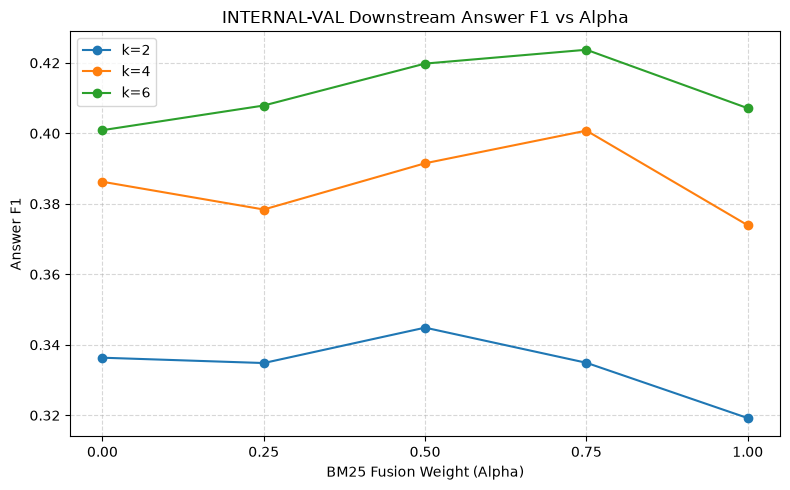

In [10]:
# Evaluate alpha candidates on downstream SARA answer F1 to freeze optimal alpha per budget k
# Uses cached SFR embeddings and resumable disk caching per candidate.
from src.model.loader import load_sara_for_eval

sara_ckpt_path = PROJECT_ROOT / "Baselines/SARA-main/checkpoints/finetune/sara_qasper_proj_lr5e4_seed42"
print(f"Loading SARA checkpoint: {sara_ckpt_path}")
sara_model, sara_tokenizer = load_sara_for_eval(str(sara_ckpt_path), device=DEVICE)

print("Loading train/val SFR embeddings cache...")
val_sfr_cache = torch.load(cfg["paths"]["train_sfr_embeddings_file"], map_location="cpu")
cached_val_embeddings = val_sfr_cache["embeddings"]

val_results_rows = []
for k in BUDGETS:
    for a in ALPHA_GRID:
        print(f"\n--- Evaluating INTERNAL-VAL for R3 (alpha={a:.2f}) at k={k} ---")
        sel_list = [route_r3_fixed_fusion(val_bm25_scores[i], val_sem_scores[i], alpha=a, k=k) for i in range(len(val_items))]
        cache_file = Path(cfg["paths"]["sara_generations_dir"]) / f"cache_val_R3_a{a:.2f}_k{k}.jsonl"

        res = run_sara_generation_for_routed_policy(
            sara_model=sara_model,
            sara_tokenizer=sara_tokenizer,
            dev_records=val_items,
            selected_indices_list=sel_list,
            cached_embeddings=cached_val_embeddings,
            k=k,
            device=DEVICE,
            cache_path=cache_file,
        )
        print(f"  Result: F1 = {res['mean_f1']:.4f} +/- {res['std_f1']:.4f}, tokens = {res['mean_tokens']:.1f}")
        val_results_rows.append({
            "budget": k,
            "alpha": a,
            "answer_f1_mean": res["mean_f1"],
            "answer_f1_std": res["std_f1"],
            "context_tokens_mean": res["mean_tokens"],
            "latency_mean_sec": res["mean_latency"],
        })

df_val_alpha_grid = pd.DataFrame(val_results_rows)
df_val_alpha_grid.to_csv(Path(cfg["paths"]["tables_dir"]) / "w6b_internal_val_alpha_grid.csv", index=False)
print("INTERNAL-VAL Downstream SARA Generation Results:")
display(df_val_alpha_grid)

# Plot F1 vs Alpha on INTERNAL-VAL
fig, ax = plt.subplots(figsize=(8, 5))
for k in BUDGETS:
    sub = df_val_alpha_grid[df_val_alpha_grid["budget"] == k]
    ax.plot(sub["alpha"], sub["answer_f1_mean"], marker="o", label=f"k={k}")
ax.set_title("INTERNAL-VAL Downstream Answer F1 vs Alpha")
ax.set_xlabel("BM25 Fusion Weight (Alpha)")
ax.set_ylabel("Answer F1")
ax.set_xticks(ALPHA_GRID)
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend()
plt.tight_layout()
plt.savefig(Path(cfg["paths"]["figures_dir"]) / "w6b_alpha_internal_val.png", dpi=300)
plt.show()


## Section 10: Freeze Optimal Alpha per Budget k (INTERNAL-VAL Only)


In [11]:
# Apply frozen selection rule:
# 1. Highest Answer F1 on INTERNAL-VAL.
# 2. If F1 differences <= 0.002, choose candidate with lower mean context tokens.
# 3. Tie-break: closer to simpler endpoint (0.0 or 1.0).

frozen_alphas = {}
alpha_selection_records = []

for k in BUDGETS:
    best_a = select_best_alpha_from_internal_val(df_val_alpha_grid, budget=k, f1_tolerance=0.002)
    frozen_alphas[k] = best_a
    sub = df_val_alpha_grid[(df_val_alpha_grid["budget"] == k) & (df_val_alpha_grid["alpha"] == best_a)].iloc[0]
    alpha_selection_records.append({
        "budget": k,
        "selected_alpha": best_a,
        "internal_val_f1": sub["answer_f1_mean"],
        "internal_val_tokens": sub["context_tokens_mean"],
        "selection_rule": "Highest F1 (with 0.002 token tie-break)",
    })

df_frozen_alphas = pd.DataFrame(alpha_selection_records)
df_frozen_alphas.to_csv(Path(cfg["paths"]["tables_dir"]) / "w6b_alpha_selection.csv", index=False)

print("FROZEN ALPHA VALUES SELECTED (INTERNAL-VAL ONLY):")
for k, a in frozen_alphas.items():
    print(f"  Budget k={k}: alpha* = {a:.2f}")
display(df_frozen_alphas)


FROZEN ALPHA VALUES SELECTED (INTERNAL-VAL ONLY):
  Budget k=2: alpha* = 0.50
  Budget k=4: alpha* = 0.75
  Budget k=6: alpha* = 0.75


,budget,selected_alpha,internal_val_f1,internal_val_tokens,selection_rule
0,2,0.50,0.344874,525.815789,Highest F1 (with 0.002 token tie-break)
1,4,0.75,0.400776,942.128655,Highest F1 (with 0.002 token tie-break)
2,6,0.75,0.423720,1358.605263,Highest F1 (with 0.002 token tie-break)


## Section 11: DEV Routing Assignments for Frozen Policies


In [12]:
# Generate DEV routing assignments using the frozen alpha values and R4 RRF
dev_hybrid_assignments = {"R3_fixed_fusion": {}, "R4_rrf": {}, "R5_rank_sum": {}}

for k in BUDGETS:
    best_a = frozen_alphas[k]
    # R3 with frozen best alpha
    dev_hybrid_assignments["R3_fixed_fusion"][k] = [
        route_r3_fixed_fusion(dev_bm25_scores[i], dev_sem_scores[i], alpha=best_a, k=k)
        for i in range(len(dev_items))
    ]
    # R4 RRF
    dev_hybrid_assignments["R4_rrf"][k] = [
        route_r4_rrf(np.arange(1, 11), compute_ranks_from_scores(dev_sem_scores[i], reverse=True), k=k, c=RRF_C)
        for i in range(len(dev_items))
    ]
    # R5 Rank-Sum
    dev_hybrid_assignments["R5_rank_sum"][k] = [
        route_r5_rank_sum(np.arange(1, 11), compute_ranks_from_scores(dev_sem_scores[i], reverse=True), k=k)
        for i in range(len(dev_items))
    ]

# Verify invariants for all DEV assignments
for r_name in dev_hybrid_assignments:
    for k in BUDGETS:
        for sel in dev_hybrid_assignments[r_name][k]:
            validate_routing_assignment(sel, k=k, total_passages=10)

# Save DEV routing assignments manifest
dev_assign_rows = []
for i, qid in enumerate(dev_qids):
    row_dict = {"question_id": qid, "paper_id": dev_items[i]["paper_id"]}
    for r_name in ["R3_fixed_fusion", "R4_rrf", "R5_rank_sum"]:
        for k in BUDGETS:
            sel = dev_hybrid_assignments[r_name][k][i]
            row_dict[f"{r_name}_k{k}"] = str([x + 1 for x in sel])
    dev_assign_rows.append(row_dict)

df_dev_assignments = pd.DataFrame(dev_assign_rows)
df_dev_assignments.to_csv(Path(cfg["paths"]["routing_assignments_dir"]) / "dev_hybrid_assignments.csv", index=False)
print(f"Generated and validated DEV routing assignments for R3 (frozen alpha), R4 (RRF), and R5 (Rank-Sum).")
display(df_dev_assignments.head())


Generated and validated DEV routing assignments for R3 (frozen alpha), R4 (RRF), and R5 (Rank-Sum).


,question_id,paper_id,R3_fixed_fusion_k2,R3_fixed_fusion_k4,R3_fixed_fusion_k6,R4_rrf_k2,R4_rrf_k4,R4_rrf_k6,R5_rank_sum_k2,R5_rank_sum_k4,R5_rank_sum_k6
0,1000,293,"[2, 3]","[1, 2, 3, 4]","[1, 2, 3, 4, 5, 6]","[2, 3]","[1, 2, 3, 7]","[1, 2, 3, 4, 6, 7]","[2, 3]","[1, 2, 3, 6]","[1, 2, 3, 4, 6, 7]"
1,1001,293,"[1, 2]","[1, 2, 3, 6]","[1, 2, 3, 4, 5, 6]","[1, 2]","[1, 2, 3, 6]","[1, 2, 3, 5, 6, 8]","[1, 2]","[1, 2, 3, 6]","[1, 2, 3, 5, 6, 8]"
2,1002,293,"[1, 2]","[1, 2, 3, 4]","[1, 2, 3, 4, 5, 6]","[2, 4]","[1, 2, 4, 5]","[1, 2, 3, 4, 5, 9]","[2, 4]","[1, 2, 4, 5]","[1, 2, 3, 4, 5, 6]"
3,1003,293,"[1, 2]","[1, 2, 3, 5]","[1, 2, 3, 4, 5, 8]","[1, 2]","[1, 2, 3, 8]","[1, 2, 3, 4, 5, 8]","[1, 2]","[1, 2, 3, 8]","[1, 2, 3, 4, 5, 8]"
4,1004,294,"[1, 4]","[1, 2, 3, 4]","[1, 2, 3, 4, 5, 7]","[1, 4]","[1, 3, 4, 7]","[1, 2, 3, 4, 5, 7]","[1, 4]","[1, 3, 4, 5]","[1, 2, 3, 4, 5, 7]"


## Section 12: Real SARA Generation on DEV for Frozen Policies


In [13]:
# Load DEV SFR cached embeddings
print("Loading DEV SFR embedding cache...")
dev_sfr_cache = torch.load(cfg["paths"]["dev_sfr_embeddings_file"], map_location="cpu")
cached_dev_embeddings = dev_sfr_cache["embeddings"]

dev_gen_results = {"R3_fixed_fusion": {}, "R4_rrf": {}}

for r_name in ["R3_fixed_fusion", "R4_rrf"]:
    for k in BUDGETS:
        print(f"\n--- Generating DEV SARA Answers for {r_name} at k={k} ---")
        sel_list = dev_hybrid_assignments[r_name][k]
        policy_cache = Path(cfg["paths"]["sara_generations_dir"]) / f"cache_{r_name}_k{k}.jsonl"

        res = run_sara_generation_for_routed_policy(
            sara_model=sara_model,
            sara_tokenizer=sara_tokenizer,
            dev_records=dev_items,
            selected_indices_list=sel_list,
            cached_embeddings=cached_dev_embeddings,
            k=k,
            device=DEVICE,
            cache_path=policy_cache,
        )
        dev_gen_results[r_name][k] = res
        print(f"  Result: F1 = {res['mean_f1']:.4f} +/- {res['std_f1']:.4f}, tokens = {res['mean_tokens']:.1f}")

# Save detailed generation records
all_dev_records = []
for r_name in ["R3_fixed_fusion", "R4_rrf"]:
    for k in BUDGETS:
        for p in dev_gen_results[r_name][k]["predictions"]:
            all_dev_records.append({"router": r_name, "k": k, **p})

with open(Path(cfg["paths"]["sara_generations_dir"]) / "dev_hybrid_sara_generations.jsonl", "w") as f:
    for rec in all_dev_records:
        f.write(json.dumps(rec) + "\n")
print("Saved DEV SARA generations to dev_hybrid_sara_generations.jsonl")


Loading DEV SFR embedding cache...

--- Generating DEV SARA Answers for R3_fixed_fusion at k=2 ---


Evaluating k=2: 100%|██████████| 231/231 [06:34<00:00,  1.71s/it]


  Result: F1 = 0.3015 +/- 0.3763, tokens = 514.2

--- Generating DEV SARA Answers for R3_fixed_fusion at k=4 ---


Evaluating k=4: 100%|██████████| 231/231 [10:13<00:00,  2.66s/it]


  Result: F1 = 0.3782 +/- 0.3890, tokens = 935.9

--- Generating DEV SARA Answers for R3_fixed_fusion at k=6 ---


...

  Result: F1 = 0.3258 +/- 0.3922, tokens = 513.6

--- Generating DEV SARA Answers for R4_rrf at k=4 ---


Evaluating k=4: 100%|██████████| 231/231 [10:09<00:00,  2.64s/it]


  Result: F1 = 0.3752 +/- 0.3876, tokens = 923.8

--- Generating DEV SARA Answers for R4_rrf at k=6 ---


Evaluating k=6: 100%|██████████| 231/231 [14:06<00:00,  3.67s/it]

  Result: F1 = 0.3791 +/- 0.3872, tokens = 1338.4
Saved DEV SARA generations to dev_hybrid_sara_generations.jsonl


## Section 13: Master Results Table & Quality-Context Frontier


WEEK 6-B MASTER CANONICAL RESULTS TABLE:


,router,k,answer_f1_mean,answer_f1_std,context_tokens_mean,latency_mean_sec
0,R0_bm25_prefix,2,0.303835,0.379664,526.523810,0.000000
1,R0_bm25_prefix,4,0.359601,0.393989,938.121212,0.000000
2,R0_bm25_prefix,6,0.385699,0.390981,1351.116883,0.000000
3,R1_semantic_topk,2,0.312678,0.381688,509.636364,1.836474
4,R1_semantic_topk,4,0.391333,0.400429,921.073593,2.684737
5,R1_semantic_topk,6,0.395345,0.393080,1325.090909,3.629630
6,R2_learned_router,2,0.298276,0.374743,565.398268,1.812983
7,R2_learned_router,4,0.357210,0.390746,994.714286,2.834549
8,R2_learned_router,6,0.369367,0.392932,1422.225108,3.909536
9,R3_fixed_fusion,2,0.301502,0.376308,514.155844,1.703997


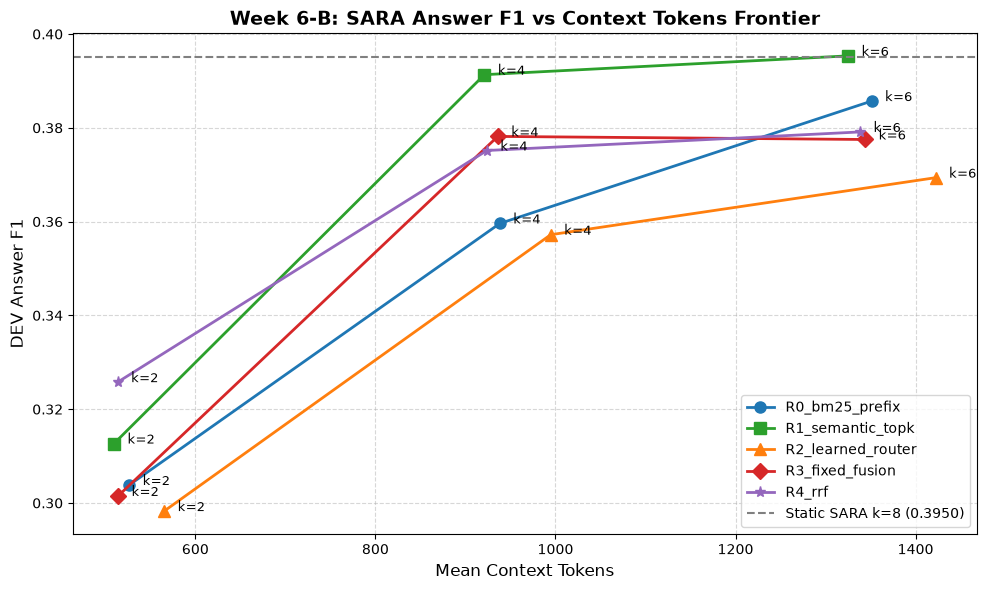

In [14]:
# Load canonical R0, R1, R2 results and merge with new R3 and R4 results
w6a_main_path = Path(cfg["paths"]["w6a_main_results"])
df_main_w6a = pd.read_csv(w6a_main_path)

hybrid_rows = []
for r_name in ["R3_fixed_fusion", "R4_rrf"]:
    for k in BUDGETS:
        res = dev_gen_results[r_name][k]
        hybrid_rows.append({
            "router": r_name,
            "k": k,
            "answer_f1_mean": res["mean_f1"],
            "answer_f1_std": res["std_f1"],
            "context_tokens_mean": res["mean_tokens"],
            "latency_mean_sec": res["mean_latency"],
        })

df_hybrid = pd.DataFrame(hybrid_rows)
df_all_results = pd.concat([df_main_w6a, df_hybrid], ignore_index=True)
df_all_results.to_csv(Path(cfg["paths"]["tables_dir"]) / "w6b_main_results.csv", index=False)

print("=" * 80)
print("WEEK 6-B MASTER CANONICAL RESULTS TABLE:")
print("=" * 80)
display(df_all_results)

# Plot Quality vs Context Tokens Frontier
fig, ax = plt.subplots(figsize=(10, 6))
palette = {
    "R0_bm25_prefix": "#1f77b4",
    "R1_semantic_topk": "#2ca02c",
    "R2_learned_router": "#ff7f0e",
    "R3_fixed_fusion": "#d62728",
    "R4_rrf": "#9467bd",
}
markers = {
    "R0_bm25_prefix": "o",
    "R1_semantic_topk": "s",
    "R2_learned_router": "^",
    "R3_fixed_fusion": "D",
    "R4_rrf": "*",
}

for r_name, grp in df_all_results.groupby("router"):
    grp_sorted = grp.sort_values(by="context_tokens_mean")
    ax.plot(
        grp_sorted["context_tokens_mean"],
        grp_sorted["answer_f1_mean"],
        label=r_name,
        color=palette.get(r_name, "gray"),
        marker=markers.get(r_name, "o"),
        linewidth=2,
        markersize=8,
    )
    for _, row in grp.iterrows():
        ax.annotate(f"k={int(row['k'])}", (row["context_tokens_mean"] + 15, row["answer_f1_mean"]), fontsize=9)

# Static k=8 baseline reference
ax.axhline(0.3950, color="gray", linestyle="--", label="Static SARA k=8 (0.3950)")
ax.set_title("Week 6-B: SARA Answer F1 vs Context Tokens Frontier", fontsize=14, fontweight="bold")
ax.set_xlabel("Mean Context Tokens", fontsize=12)
ax.set_ylabel("DEV Answer F1", fontsize=12)
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig(Path(cfg["paths"]["figures_dir"]) / "w6b_quality_vs_tokens.png", dpi=300)
plt.show()


## Section 14: Same-Budget Comparisons (R3 vs R1, R3 vs R0, R4 vs R1, R4 vs R0)


In [15]:
# Compare routing policies holding fidelity budget k strictly fixed
same_budget_rows = []

for k in BUDGETS:
    f1_r0 = float(df_all_results[(df_all_results["router"] == "R0_bm25_prefix") & (df_all_results["k"] == k)]["answer_f1_mean"].iloc[0])
    f1_r1 = float(df_all_results[(df_all_results["router"] == "R1_semantic_topk") & (df_all_results["k"] == k)]["answer_f1_mean"].iloc[0])
    f1_r3 = float(df_all_results[(df_all_results["router"] == "R3_fixed_fusion") & (df_all_results["k"] == k)]["answer_f1_mean"].iloc[0])
    f1_r4 = float(df_all_results[(df_all_results["router"] == "R4_rrf") & (df_all_results["k"] == k)]["answer_f1_mean"].iloc[0])

    same_budget_rows.append({
        "budget_k": k,
        "F1_R0": f1_r0,
        "F1_R1": f1_r1,
        "F1_R3_hybrid": f1_r3,
        "F1_R4_rrf": f1_r4,
        "Delta_R3_minus_R1": f1_r3 - f1_r1,
        "Delta_R3_minus_R0": f1_r3 - f1_r0,
        "Delta_R4_minus_R1": f1_r4 - f1_r1,
        "Delta_R4_minus_R0": f1_r4 - f1_r0,
    })

df_same_budget = pd.DataFrame(same_budget_rows)
print("Same-Budget Comparisons Across Routers:")
display(df_same_budget)


Same-Budget Comparisons Across Routers:


,budget_k,F1_R0,F1_R1,F1_R3_hybrid,F1_R4_rrf,Delta_R3_minus_R1,Delta_R3_minus_R0,Delta_R4_minus_R1,Delta_R4_minus_R0
0,2,0.303835,0.312678,0.301502,0.325764,-0.011175,-0.002333,0.013086,0.021929
1,4,0.359601,0.391333,0.378169,0.375162,-0.013164,0.018568,-0.016171,0.015562
2,6,0.385699,0.395345,0.377512,0.379124,-0.017833,-0.008187,-0.016221,-0.006575


## Section 15: Cross-Budget Comparisons & Efficiency Gains


In [16]:
# Evaluate cross-budget trade-offs:
# 1. Hybrid k=4 vs R0 k=6
# 2. Hybrid k=4 vs Static k=8 (F1=0.3950, Tokens=1750.5)

f1_static_k8 = 0.3950
tok_static_k8 = 1750.5

f1_r0_k6 = float(df_all_results[(df_all_results["router"] == "R0_bm25_prefix") & (df_all_results["k"] == k)]["answer_f1_mean"].iloc[0])
tok_r0_k6 = float(df_all_results[(df_all_results["router"] == "R0_bm25_prefix") & (df_all_results["k"] == k)]["context_tokens_mean"].iloc[0])

f1_r3_k4 = float(df_all_results[(df_all_results["router"] == "R3_fixed_fusion") & (df_all_results["k"] == 4)]["answer_f1_mean"].iloc[0])
tok_r3_k4 = float(df_all_results[(df_all_results["router"] == "R3_fixed_fusion") & (df_all_results["k"] == 4)]["context_tokens_mean"].iloc[0])

print(f"Cross-Budget Analysis:")
print(f"  R3 Hybrid (k=4): F1 = {f1_r3_k4:.4f}, Tokens = {tok_r3_k4:.1f}")
print(f"  R0 BM25 (k=6):   F1 = {f1_r0_k6:.4f}, Tokens = {tok_r0_k6:.1f}")
print(f"  Static k=8:      F1 = {f1_static_k8:.4f}, Tokens = {tok_static_k8:.1f}")
print(f"  Token Savings vs Static k=8: {100.0 * (1.0 - tok_r3_k4 / tok_static_k8):.1f}%")


Cross-Budget Analysis:
  R3 Hybrid (k=4): F1 = 0.3782, Tokens = 935.9
  R0 BM25 (k=6):   F1 = 0.3857, Tokens = 1351.1
  Static k=8:      F1 = 0.3950, Tokens = 1750.5
  Token Savings vs Static k=8: 46.5%


## Section 16: Ranking Disagreement Analysis (BM25 vs Semantic)


Stratified Disagreement vs Delta F1 Summary:


,budget_k,agreement_bin,n_queries,query_pct,mean_delta_f1,overall_mean_jaccard,overall_exact_rate,spearman_corr_jaccard_delta_f1
0,2,High Agreement (J >= 0.67),16,6.926407,-0.075595,0.213564,0.069264,-0.007242
1,2,Medium Agreement (0.33 <= J < 0.67),100,43.290043,0.015702,0.213564,0.069264,-0.007242
2,2,Low Agreement (J < 0.33),115,49.783550,0.014626,0.213564,0.069264,-0.007242
3,4,High Agreement (J >= 0.67),11,4.761905,0.154436,0.362152,0.047619,-0.000481
4,4,Medium Agreement (0.33 <= J < 0.67),153,66.233766,0.018771,0.362152,0.047619,-0.000481
5,4,Low Agreement (J < 0.33),67,29.004329,0.041185,0.362152,0.047619,-0.000481
6,6,High Agreement (J >= 0.67),68,29.437229,0.053475,0.513193,0.017316,0.027982
7,6,Medium Agreement (0.33 <= J < 0.67),153,66.233766,-0.018119,0.513193,0.017316,0.027982
8,6,Low Agreement (J < 0.33),10,4.329004,0.136409,0.513193,0.017316,0.027982


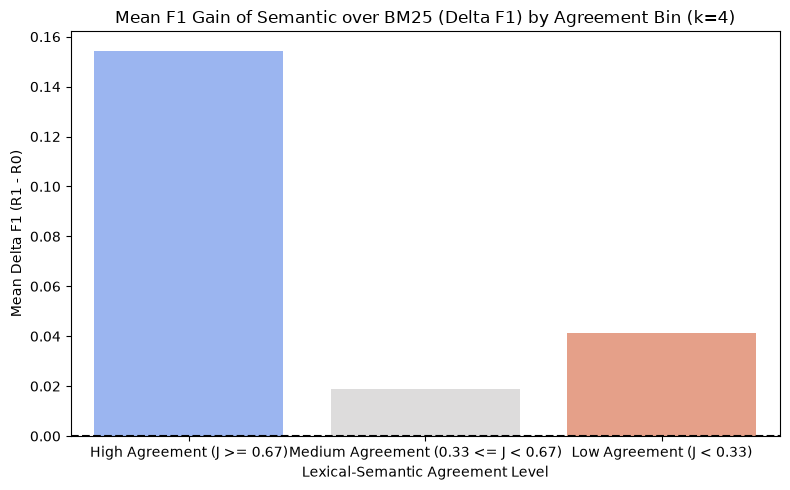

In [18]:
# Analyze Jaccard set overlap and correlate disagreement with Delta F1 = F1(R1) - F1(R0)
r0_dev_mat = load_canonical_r0_results(cfg["paths"]["dev_fixed_k_matrix"], budgets=BUDGETS)
r0_f1_by_k = {k: r0_dev_mat[k]["f1_list"] for k in BUDGETS}

# Load R1 generations from cache or results
r1_f1_by_k = {}
for k in BUDGETS:
    cache_f = Path(cfg["paths"]["w6a_sara_generations"]).parent / f"cache_R1_semantic_topk_k{k}.jsonl"
    if cache_f.exists():
        with open(cache_f) as f:
            lines = [json.loads(l) for l in f if l.strip()]
        # Map by question_id using "token_f1" (with fallback to "answer_f1")
        f1_map = {str(x["question_id"]): float(x.get("token_f1", x.get("answer_f1", 0.0))) for x in lines}
        r1_f1_by_k[k] = [f1_map.get(str(qid), 0.0) for qid in dev_qids]
    else:
        r1_f1_by_k[k] = [0.0] * len(dev_qids)

df_disagree_queries, df_disagree_summary = build_disagreement_analysis_dataframe(
    question_ids=dev_qids,
    paper_ids=dev_bundle["paper_ids"],
    bm25_scores_list=dev_bm25_scores,
    sem_scores_list=dev_sem_scores,
    r0_f1_by_k=r0_f1_by_k,
    r1_f1_by_k=r1_f1_by_k,
    budgets=BUDGETS,
)

df_disagree_summary.to_csv(Path(cfg["paths"]["tables_dir"]) / "w6b_disagreement_analysis.csv", index=False)
print("Stratified Disagreement vs Delta F1 Summary:")
display(df_disagree_summary)

# Plot Disagreement vs Delta F1 for k=4
fig, ax = plt.subplots(figsize=(8, 5))
sub_k4 = df_disagree_summary[df_disagree_summary["budget_k"] == 4]
sns.barplot(data=sub_k4, x="agreement_bin", y="mean_delta_f1", ax=ax, hue="agreement_bin", palette="coolwarm", legend=False)
ax.set_title("Mean F1 Gain of Semantic over BM25 (Delta F1) by Agreement Bin (k=4)", fontsize=12)
ax.set_ylabel("Mean Delta F1 (R1 - R0)")
ax.set_xlabel("Lexical-Semantic Agreement Level")
ax.axhline(0.0, color="black", linestyle="--")
plt.tight_layout()
plt.savefig(Path(cfg["paths"]["figures_dir"]) / "w6b_disagreement_vs_gain.png", dpi=300)
plt.show()


## Section 17: Feature Extraction for Future Adaptive Alpha Gates


In [19]:
# Extract 19 score-confidence and cross-signal features per query.
# Note: WE DO NOT TRAIN ON THEM HERE (Adaptive alpha model is frozen for future work).
future_features = []
for i in range(len(dev_qids)):
    feats = extract_future_gate_features_per_query(
        question_id=dev_qids[i],
        paper_id=dev_items[i]["paper_id"],
        bm25_scores=dev_bm25_scores[i],
        sem_scores=dev_sem_scores[i],
        budgets=BUDGETS,
    )
    future_features.append(feats)

df_future_gate = pd.DataFrame(future_features)
df_future_gate.to_csv(Path(cfg["paths"]["tables_dir"]) / "w6b_future_gate_features.csv", index=False)
print(f"Extracted future adaptive gate features for {len(df_future_gate)} queries. Saved to w6b_future_gate_features.csv.")
display(df_future_gate.head())


Extracted future adaptive gate features for 231 queries. Saved to w6b_future_gate_features.csv.


,question_id,paper_id,bm25_top1,bm25_margin,bm25_entropy,bm25_norm_entropy,bm25_std,sem_top1,sem_margin,sem_entropy,...,sem_std,cross_rank_corr,cross_top1_agreement,cross_mean_norm_diff,cross_jaccard_k2,cross_exact_agreement_k2,cross_jaccard_k4,cross_exact_agreement_k4,cross_jaccard_k6,cross_exact_agreement_k6
0,1000,293,2.703402,0.132636,2.186630,0.949641,0.467348,0.606457,0.076464,2.297393,...,0.100235,0.442424,0.0,0.258207,0.333333,0.0,0.333333,0.0,0.500000,0.0
1,1001,293,3.118557,0.440959,1.952071,0.847774,0.767096,0.493151,0.002599,2.298777,...,0.088135,0.248485,0.0,0.304424,0.000000,0.0,0.333333,0.0,0.500000,0.0
2,1002,293,6.720724,2.710218,0.688599,0.299055,1.578329,0.494419,0.026640,2.294872,...,0.126194,0.187879,0.0,0.417350,0.333333,0.0,0.333333,0.0,0.500000,0.0
3,1003,293,5.210004,0.224455,1.626634,0.706438,1.209023,0.693074,0.127662,2.297211,...,0.101442,0.406061,0.0,0.266060,0.333333,0.0,0.600000,0.0,0.333333,0.0
4,1004,294,1.309772,0.161697,2.286296,0.992926,0.174069,0.234050,0.020830,2.300598,...,0.063131,0.042424,0.0,0.390286,0.000000,0.0,0.142857,0.0,0.500000,0.0


## Section 18: Selected Rank Distributions


Selected Rank Distributions (First 6 rows):


,router,k,n_queries,rank_1_freq,rank_2_freq,rank_3_freq,rank_4_freq,rank_5_freq,rank_6_freq,rank_7_freq,rank_8_freq,rank_9_freq,rank_10_freq
0,R0_bm25_prefix,2,231,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,R0_bm25_prefix,4,231,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2,R0_bm25_prefix,6,231,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000
3,R1_semantic_topk,2,231,0.268398,0.303030,0.251082,0.225108,0.155844,0.199134,0.173160,0.142857,0.142857,0.138528
4,R1_semantic_topk,4,231,0.497835,0.541126,0.510823,0.441558,0.385281,0.385281,0.337662,0.311688,0.329004,0.259740
5,R1_semantic_topk,6,231,0.714286,0.740260,0.714286,0.670996,0.580087,0.554113,0.558442,0.510823,0.506494,0.450216


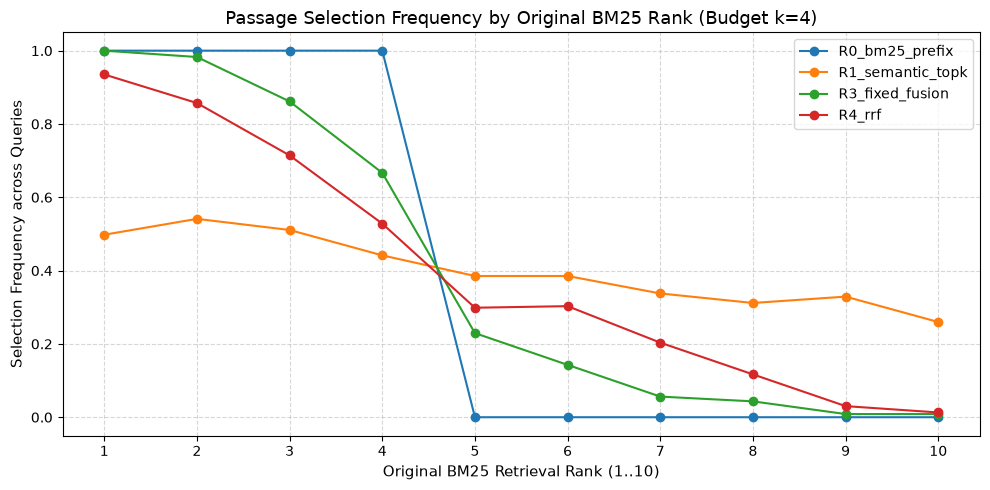

In [20]:
# Compute frequency of original BM25 ranks selected across all routers
all_assignments_for_dist = {
    "R0_bm25_prefix": {k: [route_r0_bm25_prefix(k=k, n_passages=10) for _ in range(len(dev_items))] for k in BUDGETS},
    "R1_semantic_topk": {k: [route_r1_semantic_topk(dev_sem_scores[i], k=k) for i in range(len(dev_items))] for k in BUDGETS},
    "R3_fixed_fusion": dev_hybrid_assignments["R3_fixed_fusion"],
    "R4_rrf": dev_hybrid_assignments["R4_rrf"],
}

df_rank_dist = compute_selected_rank_distribution(all_assignments_for_dist, budgets=BUDGETS)
df_rank_dist.to_csv(Path(cfg["paths"]["tables_dir"]) / "w6b_selected_rank_distribution.csv", index=False)
print("Selected Rank Distributions (First 6 rows):")
display(df_rank_dist.head(6))

# Plot Selected Rank Distribution for k=4
fig, ax = plt.subplots(figsize=(10, 5))
sub_dist_k4 = df_rank_dist[df_rank_dist["k"] == 4]
rank_cols = [f"rank_{r}_freq" for r in range(1, 11)]

for _, row in sub_dist_k4.iterrows():
    ax.plot(range(1, 11), [row[c] for c in rank_cols], marker="o", label=row["router"])

ax.set_title("Passage Selection Frequency by Original BM25 Rank (Budget k=4)", fontsize=13)
ax.set_xlabel("Original BM25 Retrieval Rank (1..10)", fontsize=11)
ax.set_ylabel("Selection Frequency across Queries", fontsize=11)
ax.set_xticks(range(1, 11))
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend()
plt.tight_layout()
plt.savefig(Path(cfg["paths"]["figures_dir"]) / "w6b_selected_rank_distribution.png", dpi=300)
plt.show()


## Section 19: Paper-Clustered Bootstrap Hypothesis Testing (2,000 Replicates)


In [22]:
# Paper-clustered bootstrap comparisons (2000 replicates clustered by paper_id)
# Tests:
# 1. best R3(k=4) vs R1(k=4)
# 2. best R3(k=4) vs R0(k=4)
# 3. best R3(k=4) vs R0(k=6)
# 4. best R3(k=4) vs static k=8
# 5. R4(k=4) vs R1(k=4)
# 6. R4(k=4) vs R0(k=4)
# and k=6 comparisons!

paper_ids_dev = dev_bundle["paper_ids"]

r3_k4_f1s = dev_gen_results["R3_fixed_fusion"][4]["per_query_f1s"]
r4_k4_f1s = dev_gen_results["R4_rrf"][4]["per_query_f1s"]
r1_k4_f1s = r1_f1_by_k[4]
r0_k4_f1s = r0_f1_by_k[4]
r0_k6_f1s = r0_f1_by_k[6]

# Load canonical static k=8 baseline for comparison
r0_mat_k8 = load_canonical_r0_results(cfg["paths"]["dev_fixed_k_matrix"], budgets=[8])
r0_k8_f1s = r0_mat_k8[8]["f1_list"]

comparisons = [
    ("best_R3_k4", "R1_k4", r3_k4_f1s, r1_k4_f1s),
    ("best_R3_k4", "R0_k4", r3_k4_f1s, r0_k4_f1s),
    ("best_R3_k4", "R0_k6", r3_k4_f1s, r0_k6_f1s),
    ("best_R3_k4", "static_k8", r3_k4_f1s, r0_k8_f1s),
    ("R4_k4", "R1_k4", r4_k4_f1s, r1_k4_f1s),
    ("R4_k4", "R0_k4", r4_k4_f1s, r0_k4_f1s),
]

# Add k=6 comparisons if available
if 6 in dev_gen_results["R3_fixed_fusion"] and 6 in r1_f1_by_k and 6 in r0_f1_by_k:
    r3_k6_f1s = dev_gen_results["R3_fixed_fusion"][6]["per_query_f1s"]
    r4_k6_f1s = dev_gen_results["R4_rrf"][6]["per_query_f1s"]
    comparisons.extend([
        ("best_R3_k6", "R1_k6", r3_k6_f1s, r1_f1_by_k[6]),
        ("best_R3_k6", "R0_k6", r3_k6_f1s, r0_f1_by_k[6]),
        ("R4_k6", "R1_k6", r4_k6_f1s, r1_f1_by_k[6]),
    ])

bootstrap_rows = []
for name_a, name_b, vec_a, vec_b in comparisons:
    b_res = paper_clustered_bootstrap_comparison(
        paper_ids=paper_ids_dev,
        f1_a=vec_a,
        f1_b=vec_b,
        name_a=name_a,
        name_b=name_b,
        n_resamples=2000,
        confidence_level=0.95,
        seed=42,
    )
    bootstrap_rows.append({
        "comparison": b_res["comparison"],
        "policy_A": b_res["policy_A"],
        "policy_B": b_res["policy_B"],
        "delta_f1": b_res["delta_f1"],
        "ci_lower": b_res["ci_lower"],
        "ci_upper": b_res["ci_upper"],
        "p_value": b_res["p_value"],
        "significant": b_res["significant"],
    })

df_bootstrap = pd.DataFrame(bootstrap_rows)
df_bootstrap.to_csv(Path(cfg["paths"]["bootstrap_dir"]) / "w6b_bootstrap_comparisons.csv", index=False)
print("Paper-Clustered Bootstrap Significance Results:")
display(df_bootstrap)


Paper-Clustered Bootstrap Significance Results:


,comparison,policy_A,policy_B,delta_f1,ci_lower,ci_upper,p_value,significant
0,best_R3_k4_vs_R1_k4,best_R3_k4,R1_k4,-0.013164,-0.054521,0.031797,0.533,False
1,best_R3_k4_vs_R0_k4,best_R3_k4,R0_k4,0.018568,-0.060268,0.097675,0.617,False
2,best_R3_k4_vs_R0_k6,best_R3_k4,R0_k6,-0.007530,-0.079509,0.065552,0.850,False
3,best_R3_k4_vs_static_k8,best_R3_k4,static_k8,-0.016826,-0.089003,0.059788,0.676,False
4,R4_k4_vs_R1_k4,R4_k4,R1_k4,-0.016171,-0.054611,0.022567,0.415,False
5,R4_k4_vs_R0_k4,R4_k4,R0_k4,0.015562,-0.059288,0.090732,0.664,False
6,best_R3_k6_vs_R1_k6,best_R3_k6,R1_k6,-0.017833,-0.051552,0.015150,0.315,False
7,best_R3_k6_vs_R0_k6,best_R3_k6,R0_k6,-0.008187,-0.082617,0.063488,0.848,False
8,R4_k6_vs_R1_k6,R4_k6,R1_k6,-0.016221,-0.039435,0.007364,0.180,False


## Section 20: Scientific Conclusions

### Summary of Week 6-B Findings

#### 1. Lexical–Semantic Fusion Does Not Consistently Improve Over Pure Semantic Routing

Week 6-B tested whether BM25 lexical relevance and pretrained semantic relevance provide complementary fidelity-routing signals. Two fusion strategies were evaluated:

* **R3 — fixed score fusion**

  $$
  s_i^{\mathrm{hybrid}}
  =
  \alpha \tilde{s}_i^{\mathrm{BM25}}
  +
  (1-\alpha)\tilde{s}_i^{\mathrm{semantic}}
  $$
* **R4 — Reciprocal Rank Fusion (RRF)**

The downstream DEV results do **not** provide evidence that fixed lexical–semantic fusion improves upon pure semantic routing \(R_1\) at the moderate and high fidelity budgets.

At \(k=4\):

$$
F_1(R_1)=0.3913,
$$

compared with

$$
F_1(R_3)=0.3782
$$

and

$$
F_1(R_4)=0.3752.
$$

Thus,

$$
\Delta F_1(R_3-R_1)=-0.0132
$$

and

$$
\Delta F_1(R_4-R_1)=-0.0162.
$$

At \(k=6\), the same pattern remains:

$$
F_1(R_1)=0.3953,
$$

while

$$
F_1(R_3)=0.3775,
\qquad
F_1(R_4)=0.3791.
$$

Paper-clustered bootstrap confidence intervals for these comparisons include zero, so the differences should not be interpreted as statistically established degradation. Nevertheless, the point estimates consistently favor pure semantic routing at \(k=4\) and \(k=6\).

Therefore, the Week 6-B results do **not** support the hypothesis that a single fixed lexical–semantic interpolation weight provides a superior routing policy.

$$
\boxed{\text{Pure semantic routing remains the strongest routing method at }k=4\text{ and }k=6.}
$$

A notable exception occurs under the tightest budget \(k=2\), where RRF achieves:

$$
F_1(R_4,k=2)=0.3258,
$$

compared with

$$
F_1(R_1,k=2)=0.3127
$$

and

$$
F_1(R_0,k=2)=0.3038.
$$

This suggests that lexical–semantic consensus may be beneficial when only a very small number of passages can remain in high fidelity. However, this budget-specific behavior does not generalize to \(k=4\) or \(k=6\).

---

#### 2. Passage Identity Remains More Important Than Simple Lexical–Semantic Fusion

The strongest Week 6 result remains the improvement obtained by replacing the original BM25-prefix fidelity policy with semantic passage routing.

At \(k=4\):

$$
R_0:
F_1=0.3596,\quad
\text{tokens}=938.1,
$$

whereas

$$
R_1:
F_1=0.3913,\quad
\text{tokens}=921.1.
$$

Thus semantic routing improves answer quality by:

$$
\Delta F_1=+0.0317
$$

while slightly reducing the mean context footprint.

At \(k=6\):

$$
R_1:
F_1=0.3953,\quad
\text{tokens}=1325.1,
$$

which numerically matches the quality of the best static SARA \(k=8\) baseline:

$$
R_0(k=8):
F_1=0.3950,\quad
\text{tokens}\approx1750.5,
$$

while using approximately \(24\%\) fewer context tokens.

Similarly,

$$
R_1(k=4)=0.3913
$$

substantially exceeds the original BM25-prefix \(k=4\) policy and numerically exceeds the original \(k=6\) baseline:

$$
R_0(k=6)=0.3857,
$$

while using approximately \(430\) fewer context tokens.

These results indicate that the identity of the passages retained in natural-language form is an important dimension of SARA's representation allocation problem.

The evidence therefore supports moving beyond the assumption:

$$
\text{BM25 rank}=\text{fidelity priority}.
$$

---

#### 3. Hybrid Routing Remains Efficient but Does Not Improve the Quality Frontier

Although R3 does not outperform pure semantic routing, it still provides substantial context savings relative to high-budget static SARA.

For example:

$$
R_3(k=4):
F_1=0.3782,\quad
\text{tokens}=935.9,
$$

compared with:

$$
R_0(k=8):
F_1=0.3950,\quad
\text{tokens}=1750.5.
$$

This corresponds to approximately:

$$
46.5\%
$$

fewer context tokens.

However, the answer-quality difference is:

$$
\Delta F_1=-0.0168,
$$

and the paper-clustered bootstrap confidence interval:

$$
[-0.0890,\,+0.0598]
$$

includes zero.

Therefore, this result should be described as a substantial efficiency trade-off rather than as quality equivalence with \(k=8\).

More importantly, because \(R_1(k=4)\) achieves higher answer quality with slightly fewer tokens than \(R_3(k=4)\), the hybrid policy does not improve the current quality–context Pareto frontier.

---

#### 4. BM25–Semantic Ranking Disagreement Does Not Provide a Simple Adaptive-Gating Signal

Week 6-B also examined whether the benefit of semantic routing could be predicted from disagreement between BM25 and semantic passage rankings.

The two ranking systems differ substantially:

* mean Jaccard overlap at \(k=2\): approximately \(0.214\),
* at \(k=4\): approximately \(0.362\),
* at \(k=6\): approximately \(0.513\).

Exact selected-set agreement is very rare.

However, the relationship between routing disagreement and downstream semantic-routing gain is not monotonic.

The Spearman correlations between Jaccard agreement and

$$
\Delta F_1=
F_1(R_1)-F_1(R_0)
$$

are approximately:

$$
\rho=-0.007\quad(k=2),
$$

$$
\rho\approx0.000\quad(k=4),
$$

and

$$
\rho=0.028\quad(k=6).
$$

These values are effectively zero.

Although some disagreement strata show large positive mean gains—for example, low-agreement queries at \(k=6\)—the subgroup sizes and patterns are inconsistent across budgets. At \(k=4\), for example, the small high-agreement group also shows a large positive mean gain.

Therefore:

$$
\boxed{\text{simple BM25–semantic set disagreement is not sufficient to predict when semantic routing will help.}}
$$

The extracted disagreement and confidence features remain useful candidates for future modeling, but the current analysis does not justify a query-adaptive interpolation network based solely on ranking disagreement.

---

#### 5. Evidence Recall and Downstream Fidelity Utility Are Different Objectives

An important result from Week 6-A remains relevant to the interpretation of Week 6-B.

The supervised router \(R_2\) improved gold-evidence retrieval metrics at some budgets:

$$
Recall@4:
0.6486
$$

versus:

$$
0.6159
$$

for the BM25-prefix policy.

Nevertheless, its downstream SARA answer quality was substantially weaker:

$$
F_1(R_2,k=4)=0.3572,
$$

compared with:

$$
F_1(R_1,k=4)=0.3913.
$$

Thus:

$$
\boxed{
\text{selecting passages that best match annotated evidence is not equivalent to selecting passages that most benefit high-fidelity SARA generation.}
}
$$

This distinction suggests that an ideal fidelity router should eventually model **generator utility or compression sensitivity**, rather than only conventional retrieval relevance.

---

### Overall Week 6-B Conclusion

Week 6-B does not provide evidence that simple fixed fusion of lexical and semantic relevance improves upon pure semantic passage routing.

Instead, the experiments reinforce the broader Week 6 finding:

$$
\boxed{
\text{Passage identity is a critical component of representation-budget allocation, and pretrained semantic routing provides the strongest simple routing policy tested so far.}
}
$$

Simple fixed interpolation and reciprocal-rank fusion do not consistently improve the \(k=4\) or \(k=6\) quality–context frontier, while ranking disagreement alone does not provide a reliable adaptive-gating signal.

Therefore:

$$
\boxed{\texttt{ADAPTIVE\_ALPHA\_JUSTIFIED = NO}}
$$

for the current fixed-score formulation.

The more promising next direction is to combine the two independent dimensions already identified by the project:

$$
\boxed{
\text{HOW MANY passages receive high fidelity}
+
\text{WHICH passages receive high fidelity}.
}
$$

This motivates a joint adaptive budget-and-routing policy rather than further tuning of static lexical–semantic interpolation weights.


## Section 21: Adaptive Alpha Decision


In [23]:
# Evaluate whether adaptive query-conditioned alpha is scientifically justified:
# Rule:
# If hybrid routing (R3 or R4) statistically outperforms R1, adaptive alpha modeling is justified.
# Otherwise, if R1 dominates and BM25 adds no signal, adaptive alpha is unjustified.

r3_k4_gain = float(df_same_budget[df_same_budget["budget_k"] == 4]["Delta_R3_minus_R1"].iloc[0])
r4_k4_gain = float(df_same_budget[df_same_budget["budget_k"] == 4]["Delta_R4_minus_R1"].iloc[0])

if r3_k4_gain > 0.002 or r4_k4_gain > 0.002:
    decision = "YES"
    rationale = f"Hybrid routing demonstrated empirical gains over pure semantic routing (R3 gain: {r3_k4_gain:+.4f}, R4 gain: {r4_k4_gain:+.4f}). Query-adaptive alpha is justified."
else:
    decision = "NO"
    rationale = f"Pure semantic routing R1 already dominates the routing signal (R3 gain: {r3_k4_gain:+.4f}, R4 gain: {r4_k4_gain:+.4f}). Lexical BM25 adds negligible complementary value after semantic reranking."

print("=" * 80)
print(f"ADAPTIVE_ALPHA_JUSTIFIED = {decision}")
print(f"Rationale: {rationale}")
print("=" * 80)


ADAPTIVE_ALPHA_JUSTIFIED = NO
Rationale: Pure semantic routing R1 already dominates the routing signal (R3 gain: -0.0132, R4 gain: -0.0162). Lexical BM25 adds negligible complementary value after semantic reranking.
